# 11. HD현대 제19회 EB — 평가 및 헤지 시뮬레이션
**목적** ① 발행가 100에 내재된 변동성 ② 발행가 100의 구성 ③ 투자 100억 델타 헤지의 1년 손익 분포

**상품** 교환대상 HD현대마린솔루션(443060) · 교환가 247,000원 · 표면 · 만기이자 0% · 만기 2031-11-26 · 투자자 조기상환청구(풋) 8회 · 발행사 중도상환(콜): 직전 10거래일 연속 종가 > 교환가 × 130%

**전제**
- 평가일 2026-11-26(납입일) · 시장 자료 기준일 2026-10-27(발행 결의일) · 부도 시 회수율 40%
- 모형: V_t + (r−q)S·V_S + ½σ²S²·V_SS − (r+λ)V + 40λ = 0 — HD현대 부도 시 40 수령, 교환대상 주가는 부도와 무관(η = 0)
- 날짜별 권리 적용 순서: 콜(평일 종가 ≥ 321,100원이면 V ≤ max(100, c·S)) → 교환(V ≥ c·S) → 풋(청구 마감일, V ≥ 지급일까지의 채권가치)
- 콜 조건은 경로 의존적이므로 즉시 콜(가격 하한)과 콜 없음(가격 상한)의 범위로 제시
- 계산 함수: `eb_model.py`(EB 조건 · 권리 규칙 · 트리 · 헤지 MC), `numerical_engine.py`(FDM), `cb_tree_model.py`(채권가치 · 내재변동성 역산 · 점검)

In [1]:
import sys, math, platform
from datetime import datetime, timedelta, timezone
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
sys.path.insert(0, '.')
import cb_tree_model as cb, eb_model as eb, numerical_engine as sl, plot_style as rs
rs.apply_style(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
PROJ = Path('..'); INP, OUT = PROJ / 'work' / 'nb_out', PROJ / 'results'; OUT.mkdir(exist_ok=True)   # 입력(기존 평가 결과) · 출력(결과표)
C1, C2, C3 = '#A9AFB8', '#3D78CF', rs.NAVY                       # 그림 색: 연회색 · 파랑 · 네이비
EBT = eb.EB                                                       # EB 조건 (eb_model.EBTerms, 공시 항목 번호 표기)

CFG = dict(
    mkt_date = '20261027', val = EBT.issue,           # 시장 자료 기준일 · 평가일
    notional = 10_000_000_000,                        # 투자 100억
    grid = (1600, 2520), grid_fine = (3200, 5040),    # FDM (주가 칸, 시간 칸): 기준 격자 · 2배 격자 (풋 · 콜 날짜는 시간 칸에 고정)
    tree_n = 4000, tree_band = (8000, 16000, 24000),  # 대조용 트리 칸 수 (콜 포함 단계는 3개 칸 수의 평균)
    iv_lo = 0.05, iv_hi = 1.50, iv_tol = 1e-4,        # 내재변동성 역산 범위 · 가격 허용 오차
    mc_n = 10_000, mc_days = 252, seed = 20261107,    # 경로 1만 개 · 252영업일(1년) · 난수 시드
    sell_tax = 0.0020, k_tick = 0.5, borrow = 0.005, Y = 1.0,   # 거래비용: 10번 기준안과 동일
    bidask = 0.0037,                                  # 청산 반영 시 EB 매도 호가 차이 0.37% (논문 p.34, 10번 cb_bidask와 같은 값)
    hv_n = 252, sd_n = 60, adv_n = 60,                # HV 252일 · σ_D 60일 · 평균 거래량 60일
    disc_ratio = 0.0001, disc_min = 1e8, disc_amt = 1e9,   # 공매도 잔고 공시: 상장주식 0.01%(1억원 미만 제외) 또는 10억원 (2024-12-01)
    kis_daily = PROJ / 'data' / '20261109' / '082859_daily_443060_org__output2_raw.csv',   # KIS 일봉 원주가 (tr_id FHKST03010100)
    kis_adj   = PROJ / 'data' / '20261109' / '082857_daily_443060_adj__output2_raw.csv',   # 같은 기간 수정주가 (대조용)
    kis_info  = PROJ / 'data' / '20261109' / '082859_daily_443060_org__output1_raw.csv',   # 상장주식수 (lstn_stcn, 조회 시점)
    ecos_file = PROJ / 'data' / '20261103' / 'ecos_817Y002_ktb_daily_20260707_20261102.csv',   # 국고채 금리 (한국은행 ECOS)
    kofia = PROJ / 'data' / '20261103' / 'kofia_AA-_5y_4사평균.xls',                            # 금융투자협회 AA- 5년 4사 평균 원자료
)
chk = cb.Checker('11')
def show(df, fmt={}):                                 # 표시 형식만 지정 (값은 변경 없음)
    v = df.copy()
    for k, f in fmt.items(): v[k] = v[k].map(lambda x: '—' if pd.isna(x) else f.format(x))
    display(v)
print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · 실행 {datetime.now(timezone(timedelta(hours=9))):%Y-%m-%d %H:%M} KST")

Python 3.13.18 · numpy 2.5.3 · pandas 3.0.5 · 실행 2026-11-10 09:26 KST


## 1. 입력 자료 및 검증
- 출처: 공시 조건(DART 원문 → work/51) · 국고 금리(ECOS) · AA- 5년(금융투자협회 → 01_daily) · 배당(DART → work/53) · 시세(KIS 일봉)
- 평가일 11/26 · 시장 자료 10/27: 발행 조건이 확정된 시점의 시장 자료로 투자자 납입일의 가치를 평가
- 평가 주가 = 10/27 종가 − 900원: 배당기준일(11/10)이 평가일(11/26) 이전이라 EB 투자자에게 귀속되지 않음(현금배당 시 교환가 조정 없음)
- 배당수익률 q = 최근 결의 4회(결산 1 · 분기 3) 합계 ÷ 평가 주가 · 부도강도 λ = s ÷ (1 − 40%) (신용스프레드 = 부도확률 × 손실률, 논문 eq.47) · r · s는 10번과 같은 기준 A
- 참고 기록(ℹ, 결과에 미반영): 10/26 하루(표본 최대 하락)를 뺀 HV252 · σ_D, 평가 주가를 1개월 선도가로 둘 때의 내재변동성(3절)

In [2]:
# 1-1 EB 조건 = 공시 원문
T51 = pd.read_csv(PROJ / 'work' / '51_eb_terms_dart.csv', encoding='utf-8-sig').set_index('항목')
DOC, NOTE = T51['값'], T51['비고']                                   # 공시 원문 값 · 비고
d_ = lambda x: datetime.strptime(str(x).strip()[:10], '%Y-%m-%d').date()
def nxt(d):                                                       # 비영업일이면 다음 영업일 (공시 '익영업일')
    while d.weekday() >= 5: d += timedelta(days=1)
    return d
chk.check('교환가 (§9)', EBT.exch_price, float(DOC['교환가액']))
chk.check('발행일 · 만기일 (§11 · §5)', (EBT.issue, EBT.maturity) == (d_(DOC['납입일(발행일)']), d_(DOC['만기일'])), True)
chk.check('교환청구기간 (§9)', (EBT.exch_start, EBT.exch_end) == (d_(DOC['교환청구기간 시작']), d_(DOC['교환청구기간 종료'])), True)
chk.check('풋 지급일 8회 (§19)', list(EBT.puts) == [nxt(d_(DOC[f'{i}차 조기상환일'])) for i in range(1, 9)], True)
chk.check('풋 청구 마감일 8회 (§19)', list(EBT.put_claim) == [nxt(d_(NOTE[f'{i}차 조기상환일'].split('~')[1])) for i in range(1, 9)], True)
chk.check('콜 행사기간 (§9-1)', (EBT.call_start, EBT.call_end) == tuple(d_(x) for x in DOC['중도상환청구권 행사기간'].split('~')), True)
chk.check('콜 기준 주가 = 교환가 × 130%', EBT.call_trigger * EBT.exch_price, float(DOC['조건 주가(현재 교환가 기준)']), 1e-6)
chk.check('표면 · 만기이자 0% (§4)', float(DOC['표면이자율']) + float(DOC['만기이자율']), 0.0)
chk.check('교환대상 주식수 = 권면총액 ÷ 교환가', EBT.issue_total / EBT.exch_price, float(DOC['교환대상 주식수']), 1e-6)

# 1-2 금리 · 신용스프레드 · 배당
E = pd.read_csv(CFG['ecos_file'], dtype={'조회일자': str}, encoding='utf-8-sig'); E = E[E['조회일자'] == CFG['mkt_date']]
curve = {int(n[4:-2]): float(v) for n, v in zip(E['항목명'], E['값'])}       # '국고채(5년)' → 5
D01 = pd.read_csv(INP / '01_daily.csv', dtype={'일자': str}, encoding='utf-8-sig').set_index('일자').loc[CFG['mkt_date']]
TT = cb.yf(CFG['val'], EBT.maturity)
r = cb.interp_ktb(curve, TT) / 100                                        # 국고 금리를 잔존 만기에 직선 보간
s = (D01['AA5'] - curve[5]) / 100                                         # AA- 5년 − 국고 5년
chk.check('국고 5년: ECOS = 01_daily', curve[5], D01['ktb5'], 1e-12)
KF = pd.read_excel(CFG['kofia'], header=None).iloc[3:, :2]; KF = pd.Series(KF[1].astype(float).values, index=KF[0].astype(str).str.replace('/', ''))
chk.check('AA- 5년: 금융투자협회 원자료 = 01_daily', float(KF.loc[CFG['mkt_date']]), D01['AA5'], 1e-12)
DV = pd.read_csv(PROJ / 'work' / '53_443060_dividends_dart.csv', encoding='utf-8-sig')
dv = DV[DV['이사회결의일'] <= '2026-10-27'].sort_values('배당기준일').tail(4)   # 기준일까지 결의된 최근 4회
DPS = float(dv['1주당배당금_원'].sum())
DIV_PRE = float(DV[(DV['배당기준일'] > '2026-10-27') & (DV['배당기준일'] <= str(CFG['val']))]['1주당배당금_원'].sum())   # 평가일 이전 배당 (EB 투자자 미귀속)
chk.check('연간 배당 = 최근 결의 4회 합계', DPS, 4550.0)
print(f"국고 금리(%) {curve} · 잔존 만기 {TT:.4f}년 · 최근 4회 배당 {list(dv['1주당배당금_원'])}원 · 평가일 이전 배당 {DIV_PRE:,.0f}원")

✓ 교환가 (§9): 247000.0 | 기대 247000.0
✓ 발행일 · 만기일 (§11 · §5): True | 기대 True
✓ 교환청구기간 (§9): True | 기대 True
✓ 풋 지급일 8회 (§19): True | 기대 True
✓ 풋 청구 마감일 8회 (§19): True | 기대 True
✓ 콜 행사기간 (§9-1): True | 기대 True
✓ 콜 기준 주가 = 교환가 × 130%: 321100.0 | 기대 321100.0 ±1e-06
✓ 표면 · 만기이자 0% (§4): 0.0 | 기대 0.0
✓ 교환대상 주식수 = 권면총액 ÷ 교환가: 2383269.0 | 기대 2383269.0 ±1e-06
✓ 국고 5년: ECOS = 01_daily: 3.899 | 기대 3.899 ±1e-12
✓ AA- 5년: 금융투자협회 원자료 = 01_daily: 4.547 | 기대 4.547 ±1e-12
✓ 연간 배당 = 최근 결의 4회 합계: 4550.0 | 기대 4550.0
국고 금리(%) {1: 3.622, 2: 3.716, 3: 3.758, 5: 3.899, 10: 4.032} · 잔존 만기 5.0027년 · 최근 4회 배당 [1850, 900, 900, 900]원 · 평가일 이전 배당 900원


In [3]:
# 1-3 KIS 일봉: 종가 · HV252 · 과거 수익률 · σ_D · 거래량 · 교환가 재계산
K0 = pd.read_csv(CFG['kis_daily'], dtype={'stck_bsop_date': str}, encoding='utf-8-sig')
KA = pd.read_csv(CFG['kis_adj'], dtype={'stck_bsop_date': str}, encoding='utf-8-sig')
chk.check('수정주가 = 원주가 (상장 후 수정 사유 없음)', bool(len(K0) == len(KA) and (K0['stck_clpr'] == KA['stck_clpr']).all()), True)
K = pd.DataFrame({'일자': K0['stck_bsop_date'], 'S': K0['stck_clpr'].astype(float), '거래량': K0['acml_vol'].astype(float),
                  '거래대금': K0['acml_tr_pbmn'].astype(float)}).sort_values('일자').reset_index(drop=True)
NLIST = float(pd.read_csv(CFG['kis_info'], encoding='utf-8-sig')['lstn_stcn'].iloc[0])
md_ = CFG['mkt_date']; i0 = int(K.index[K['일자'] == md_][0]); KX = K.set_index('일자')
S0 = KX.loc[md_, 'S']
HV, hv_from = cb.hv(KX['S'], md_, CFG['hv_n'])
LR = np.log(K['S'] / K['S'].shift())
RET = LR.iloc[i0 - CFG['hv_n'] + 1: i0 + 1].to_numpy()                   # 시나리오 S3 표본 (HV252와 같은 252개)
SD60 = float(LR.iloc[i0 - CFG['sd_n'] + 1: i0 + 1].std(ddof=1))         # σ_D: 60일 로그수익률 표준편차 (시장충격용)
ADV = K['거래량'].iloc[i0 - CFG['adv_n'] + 1: i0 + 1].mean()            # 60일 평균 거래량
def vwap(a, b):                                                       # 가중평균주가 = 거래대금 합 ÷ 거래량 합, 기간 (a, b]
    x = K[(K['일자'] > a) & (K['일자'] <= b)]; return x['거래대금'].sum() / x['거래량'].sum()
v1m, v1w, v1d = vwap('20260926', '20261026'), vwap('20261019', '20261026'), vwap('20261025', '20261026')   # §9 산식: 10/26 기산 1개월 · 1주일 · 최근일
base = max((v1m + v1w + v1d) / 3, v1d); xp = math.ceil(base * 1.3 / eb.krx_tick(base * 1.3)) * eb.krx_tick(base * 1.3)
chk.check('교환가 재계산 = 247,000원 (§9)', float(xp), EBT.exch_price)
chk.check('일봉 608영업일 (2024-05-08 상장 ~ 2026-11-06)', (len(K), K['일자'].iloc[0], K['일자'].iloc[-1]) == (608, '20240508', '20261106'), True)
chk.check('10/27 종가 = 기록값', S0, 176_700.0)
chk.check('HV252 = 기록값 63.19%', HV, 0.6319, 5e-5)
chk.check('HV252 표본 시작일 = 2025-10-16', hv_from, '20251016')
chk.check('S3 표본 252개 = HV252 표본', len(RET) == 252 and abs(RET.std(ddof=1) * math.sqrt(252) - HV) < 1e-12, True)
j26 = int(K.index[K['일자'] == '20261026'][0])                             # 10/26: 252일 표본의 최대 하락일 (이사회결의 전일)
RX = np.delete(RET, j26 - (i0 - CFG['hv_n'] + 1)); SX = np.delete(LR.iloc[i0 - CFG['sd_n'] + 1: i0 + 1].to_numpy(), j26 - (i0 - CFG['sd_n'] + 1))
chk.check('10/26 = 252일 표본의 최대 하락일', bool(LR[j26] == RET.min()), True)
chk.check(f"참고: 10/26({LR[j26]:+.2%}) 제외 시 HV252 {RX.std(ddof=1) * math.sqrt(252):.2%} · σ_D {SX.std(ddof=1):.4%} (기준 {HV:.2%} · {SD60:.4%})", RX.std(ddof=1) * math.sqrt(252), kind='info')
print(f"교환가 재계산: 가중평균주가 1개월 {v1m:,.2f} · 1주일 {v1w:,.2f} · 최근일 {v1d:,.2f} → 기준주가 {base:,.2f} × 130% → {xp:,.0f}원")

✓ 수정주가 = 원주가 (상장 후 수정 사유 없음): True | 기대 True
✓ 교환가 재계산 = 247,000원 (§9): 247000.0 | 기대 247000.0
✓ 일봉 608영업일 (2024-05-08 상장 ~ 2026-11-06): True | 기대 True
✓ 10/27 종가 = 기록값: 176700.0 | 기대 176700.0
✓ HV252 = 기록값 63.19%: 0.6318702406335976 | 기대 0.6319 ±5e-05
✓ HV252 표본 시작일 = 2025-10-16: 20251016 | 기대 20251016
✓ S3 표본 252개 = HV252 표본: True | 기대 True
✓ 10/26 = 252일 표본의 최대 하락일: True | 기대 True
ℹ 참고: 10/26(-14.72%) 제외 시 HV252 61.58% · σ_D 3.1734% (기준 63.19% · 3.6832%): 0.6158358745335971
교환가 재계산: 가중평균주가 1개월 208,574.37 · 1주일 187,892.51 · 최근일 173,082.78 → 기준주가 189,849.89 × 130% → 247,000원


In [4]:
# 1-4 평가 입력값
SV = S0 - DIV_PRE                                                        # 평가 주가 = 10/27 종가 − 평가일 이전 배당
lam = s / (1 - EBT.recovery); c = 100 / EBT.exch_price; q = DPS / SV
INP = pd.DataFrame([
    ('평가 주가', f'{SV:,.0f}원', f'10/27 종가 {S0:,.0f}원 − 11/10 기준 배당 {DIV_PRE:,.0f}원'),
    ('패리티 · 교환 프리미엄', f'{c * SV:.2f} · {100 / (c * SV) - 1:.1%}', '패리티 = 평가 주가 ÷ 교환가 × 100'),
    ('무위험금리 r', f'{r:.4%}', f'국고 금리 직선 보간, 잔존 만기 {TT:.4f}년'),
    ('신용스프레드 s · 부도강도 λ', f'{s:.4%} · {lam:.4%}', 'AA- 5년 − 국고 5년 · λ = s ÷ (1 − 40%)'),
    ('배당수익률 q', f'{q:.4%}', f'연 {DPS:,.0f}원 ÷ 평가 주가'),
    ('HV252 · σ_D', f'{HV:.2%} · {SD60:.4%}', f'{hv_from} ~ {md_}'),
    ('60일 평균 거래량 · 상장주식수', f'{ADV:,.0f}주 · {NLIST:,.0f}주', 'KIS 일봉 · 상장주식수')], columns=['항목', '값', '산출 근거'])
show(INP)
P = lambda sg, **kw: eb.setup(SV, sg, r, q, s, CFG['val'], **kw)       # 변동성 · 가정 → 모형 입력

,항목,값,산출 근거
0,평가 주가,"175,800원","10/27 종가 176,700원 − 11/10 기준 배당 900원"
1,패리티 · 교환 프리미엄,71.17 · 40.5%,패리티 = 평가 주가 ÷ 교환가 × 100
2,무위험금리 r,3.8991%,"국고 금리 직선 보간, 잔존 만기 5.0027년"
3,신용스프레드 s · 부도강도 λ,0.6480% · 1.0800%,AA- 5년 − 국고 5년 · λ = s ÷ (1 − 40%)
4,배당수익률 q,2.5882%,"연 4,550원 ÷ 평가 주가"
5,HV252 · σ_D,63.19% · 3.6832%,20251016 ~ 20261027
6,60일 평균 거래량 · 상장주식수,"100,645주 · 44,833,460주",KIS 일봉 · 상장주식수


## 2. 평가 엔진 검증 (σ = HV252)
- EB는 교환 · 풋 · 콜이 결합되어 닫힌 식이 없음 → 닫힌 식이 있는 단계에서 출발해 권리를 하나씩 추가하며, 풀이 엔진은 독립적으로 구현하고 권리 규칙(EBRule) · 입력만 공유하는 FDM과 이항 트리를 단계마다 대조
- 오차 발생 시 원인이 되는 권리를 단계별로 식별 가능

| 단계 | 대조 대상 | 허용 오차 |
|---|---|---|
| E0 채권 · E1 + 만기 교환 | 닫힌 식 | 0.005p |
| E2 + 기간 중 교환 · E3 + 풋 | 트리 4,000칸 | 0.01p |
| E4 + 콜(즉시) | 트리 8,000 · 16,000 · 24,000칸 평균 (콜 기준 주가로 트리 값이 칸 수에 따라 진동) | 0.05p |

- 콜 조건 부등호: 공시는 '종가 > 321,100원'. FDM은 트리거를 칸 위에 놓고 그 칸을 포함(≥)해야 경계가 트리거에 정확히 놓임 → '>'(트리거 칸 제외)와의 차이를 기준 · 2배 격자로 기록(격자를 키우면 줄어드는 격자 오차인지 확인)

In [5]:
pH = P(HV); G, GF = CFG['grid'], CFG['grid_fine']; TN = f"트리 {CFG['tree_n']:,}칸"
tavg = lambda p_, **kw: [eb.price_tree(p_, N=n, **kw)['price'] for n in CFG['tree_band']]
LAD = [('E0 채권', '닫힌 식', dict(exch='none', puts=False, call=False), cb.bf_recovery(r, s, TT), 0.005),
       ('E1 + 만기 교환', '닫힌 식', dict(exch='euro', puts=False, call=False), eb.euro_exact(pH), 0.005),
       ('E2 + 기간 중 교환', TN, dict(puts=False, call=False), None, 0.01),
       ('E3 + 풋', TN, dict(call=False), None, 0.01),
       ('E4 + 콜(즉시)', '트리 3개 평균', dict(), None, 0.05)]
rows = []
for lab, ref_nm, kw, ref, tol in LAD:
    f = eb.price_fdm(pH, M=G[0], NT=G[1], **kw); t = eb.price_tree(pH, N=CFG['tree_n'], **kw)
    if ref_nm == '닫힌 식': chk.check(f'{lab}: {TN} − 닫힌 식', abs(t['price'] - ref), 0.0, tol)
    elif ref_nm == TN: ref = t['price']
    else:
        tv = tavg(pH, **kw); ref = float(np.mean(tv))
        f2 = eb.price_fdm(pH, M=GF[0], NT=GF[1], **kw)['price']
        chk.check(f'{lab}: FDM 기준 격자 − 2배 격자', abs(f['price'] - f2), 0.0, 0.02)
    chk.check(f'{lab}: FDM − {ref_nm}', abs(f['price'] - ref), 0.0, tol)
    chk.check(f'{lab}: delta FDM − {TN}', abs(f['delta'] - t['delta']), 0.0, 0.005)
    rows.append({'단계': lab, '대조 대상': ref_nm, '대조값': ref, 'FDM': f['price'], '차이': f['price'] - ref, '허용 오차': tol,
                 'delta (FDM)': f['delta'], f'delta ({TN})': t['delta']})
LADDER = pd.DataFrame(rows)
show(LADDER, {'대조값': '{:.4f}', 'FDM': '{:.4f}', '차이': '{:+.4f}', '허용 오차': '±{:.3f}', 'delta (FDM)': '{:.4f}', f'delta ({TN})': '{:.4f}'})
print(f"E4: 트리 8,000 · 16,000 · 24,000칸 값의 폭 {max(tv) - min(tv):.3f}p · FDM {GF[0]}×{GF[1]} {f2:.4f}")
v = LADDER['FDM']                                                    # 풋(투자자 권리) 추가 → 상승, 콜(발행사 권리) 추가 → 하락
chk.check('풋 추가 시 상승 · 콜 추가 시 하락', bool(v[2] <= v[3] and v[4] <= v[3]), True)
p1 = P(HV, eta=1)
chk.check('E1 (η = 1): FDM − 닫힌 식', abs(eb.price_fdm(p1, exch='euro', puts=False, call=False)['price'] - eb.euro_exact(p1)), 0.0, 0.005)
def fdm_gt(p_, M, NT):                                              # 콜 조건 '>'(트리거 칸 제외)로 푼 E4 — 비교용
    e_ = p_['ev']; rule = eb.EBRule(e_, p_['c'], p_['trig'] * (1 + 1e-9), True, True, True)
    kn = [e_['xs'], e_['xe'], e_['cs'], e_['ce'], *e_['puts'], *e_['mon']]
    return sl.fdm(p_['S'], p_['sigma'], e_['T'], p_['drift'], p_['rho'], p_['src'], eb._term(p_, 'amer'), rule, knots=kn, M=M, NT=NT, align=p_['trig'])['price']
g1, g2 = fdm_gt(pH, *G) - v[4], fdm_gt(pH, *GF) - f2
chk.check("콜 '>' − '≥' 차이가 2배 격자에서 줄어듦 (격자 오차 → '≥' 유지)", bool(abs(g2) < 0.6 * abs(g1)), True)
chk.check(f"참고: 콜 '>' − '≥' (E4, σ = HV252) 기준 격자 {g1:+.4f}p · 2배 격자 {g2:+.4f}p", g1, kind='info')

✓ E0 채권: 트리 4,000칸 − 닫힌 식: 4.6644627815339845e-05 | 기대 0.0 ±0.005
✓ E0 채권: FDM − 닫힌 식: 0.0008756762486825664 | 기대 0.0 ±0.005
✓ E0 채권: delta FDM − 트리 4,000칸: 0.0 | 기대 0.0 ±0.005
✓ E1 + 만기 교환: 트리 4,000칸 − 닫힌 식: 0.0012555980540014389 | 기대 0.0 ±0.005
✓ E1 + 만기 교환: FDM − 닫힌 식: 0.002957883873492051 | 기대 0.0 ±0.005
✓ E1 + 만기 교환: delta FDM − 트리 4,000칸: 7.17963805053623e-05 | 기대 0.0 ±0.005
✓ E2 + 기간 중 교환: FDM − 트리 4,000칸: 0.005286641469027131 | 기대 0.0 ±0.01
✓ E2 + 기간 중 교환: delta FDM − 트리 4,000칸: 8.08371357973181e-05 | 기대 0.0 ±0.005
✓ E3 + 풋: FDM − 트리 4,000칸: 0.005803974176870952 | 기대 0.0 ±0.01
✓ E3 + 풋: delta FDM − 트리 4,000칸: 9.604469520840819e-05 | 기대 0.0 ±0.005
✓ E4 + 콜(즉시): FDM 기준 격자 − 2배 격자: 0.004113506730377026 | 기대 0.0 ±0.02
✓ E4 + 콜(즉시): FDM − 트리 3개 평균: 0.024600712205653963 | 기대 0.0 ±0.05
✓ E4 + 콜(즉시): delta FDM − 트리 4,000칸: 0.00025719158123715946 | 기대 0.0 ±0.005


,단계,대조 대상,대조값,FDM,차이,허용 오차,delta (FDM),"delta (트리 4,000칸)"
0,E0 채권,닫힌 식,79.8640,79.8649,+0.0009,±0.005,0.0000,0.0000
1,E1 + 만기 교환,닫힌 식,106.7558,106.7529,-0.0030,±0.005,0.5791,0.5792
2,E2 + 기간 중 교환,"트리 4,000칸",108.6630,108.6577,-0.0053,±0.010,0.6372,0.6372
3,E3 + 풋,"트리 4,000칸",112.6748,112.6690,-0.0058,±0.010,0.6034,0.6035
4,E4 + 콜(즉시),트리 3개 평균,110.8119,110.7873,-0.0246,±0.050,0.5851,0.5849


E4: 트리 8,000 · 16,000 · 24,000칸 값의 폭 0.068p · FDM 3200×5040 110.7914
✓ 풋 추가 시 상승 · 콜 추가 시 하락: True | 기대 True
✓ E1 (η = 1): FDM − 닫힌 식: 0.0029787885696919147 | 기대 0.0 ±0.005
✓ 콜 '>' − '≥' 차이가 2배 격자에서 줄어듦 (격자 오차 → '≥' 유지): True | 기대 True
ℹ 참고: 콜 '>' − '≥' (E4, σ = HV252) 기준 격자 +0.0628p · 2배 격자 +0.0315p: 0.06284435485241602


## 3. 내재변동성 및 가격 구성
- 콜 조건(10거래일 연속 · 공고)은 경로 의존적이므로 두 극단으로 범위를 산출: 즉시 콜(발행사에 가장 유리, 가격 하한) · 콜 없음(가격 상한)
- 가격 = 100이 되는 σ를 두 가정으로 역산. 이후 기준 σ는 즉시 콜 내재변동성(높은 쪽 → HV252와의 차이, 즉 기대 헤지 이익을 작게 산정)
- 가격 구성은 채권 → 풋 → 교환권 → 콜 순서로 권리를 더할 때의 증가분 (더하는 순서가 바뀌면 배분이 달라짐)

,콜 가정,내재변동성,HV252 대비
0,콜 없음,38.92%,-24.27%p
1,즉시 콜,39.84%,-23.35%p


ℹ 참고: 평가 주가를 1개월 선도가 176,367원으로 둘 때 즉시 콜 내재변동성 39.60% (기준 175,800원 · 39.84%): 0.3960443496704102


,σ = 내재변동성 39.84%,σ = HV252 63.19%
채권 (부도 시 40 회수),79.8640,79.8640
풋,7.4545,7.4545
교환권,13.1711,25.3505
가격 (콜 없음),100.4896,112.6690
콜,-0.4896,-1.8817
가격 (즉시 콜),100.0000,110.7873
delta (콜 없음),0.4661,0.6034
delta (즉시 콜),0.4588,0.5851


✓ 트리 3개 평균 (즉시 콜, σ = 내재변동성) ≈ 100: 100.00504825477043 | 기대 100.0 ±0.05
σ = HV252 적용 시 가격 110.79 ~ 112.67 (발행가 대비 +10.79 ~ +12.67p)


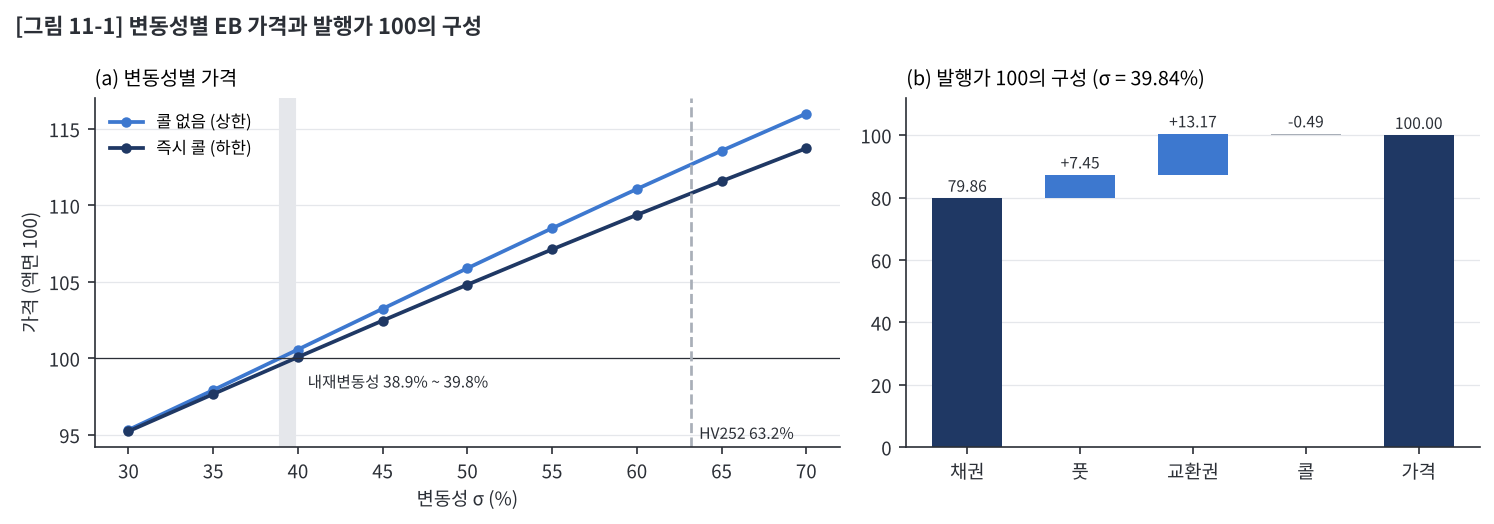

In [6]:
IV = {lab: cb.implied_vol(lambda v, cl=cl: eb.price_fdm(P(v), call=cl)['price'], 100.0, CFG['iv_lo'], CFG['iv_hi'], CFG['iv_tol'])[0]
      for lab, cl in [('콜 없음', False), ('즉시 콜', True)]}
SIG = IV['즉시 콜']
IVT = pd.DataFrame([{'콜 가정': k, '내재변동성': x, 'HV252 대비': x - HV} for k, x in IV.items()])
show(IVT, {'내재변동성': '{:.2%}', 'HV252 대비': '{:+.2%}p'})
SVF = S0 * math.exp(r * cb.yf(datetime.strptime(md_, '%Y%m%d').date(), CFG['val'])) - DIV_PRE   # 10/27 → 11/26 선도가 − 배당 (현물 유지 가정과 비교)
IVF = cb.implied_vol(lambda v: eb.price_fdm(eb.setup(SVF, v, r, DPS / SVF, s, CFG['val']))['price'], 100.0, CFG['iv_lo'], CFG['iv_hi'], CFG['iv_tol'])[0]
chk.check(f"참고: 평가 주가를 1개월 선도가 {SVF:,.0f}원으로 둘 때 즉시 콜 내재변동성 {IVF:.2%} (기준 {SV:,.0f}원 · {IV['즉시 콜']:.2%})", IVF, kind='info')

def parts(sg):                                       # 채권 → + 풋 → + 교환권 → + 콜
    p_ = P(sg); bond = cb.bf_recovery(r, s, TT)
    bput = eb.price_fdm(p_, exch='none', call=False)['price']
    nc, wc = eb.price_fdm(p_, call=False), eb.price_fdm(p_)
    return {'채권 (부도 시 40 회수)': bond, '풋': bput - bond, '교환권': nc['price'] - bput, '가격 (콜 없음)': nc['price'],
            '콜': wc['price'] - nc['price'], '가격 (즉시 콜)': wc['price'], 'delta (콜 없음)': nc['delta'], 'delta (즉시 콜)': wc['delta']}
DEC = pd.DataFrame({f'σ = 내재변동성 {SIG:.2%}': parts(SIG), f'σ = HV252 {HV:.2%}': parts(HV)})
display(DEC.round(4))
chk.check('트리 3개 평균 (즉시 콜, σ = 내재변동성) ≈ 100', float(np.mean(tavg(P(SIG)))), 100.0, 0.05)
print(f"σ = HV252 적용 시 가격 {DEC.iloc[5, 1]:.2f} ~ {DEC.iloc[3, 1]:.2f} (발행가 대비 +{DEC.iloc[5, 1] - 100:.2f} ~ +{DEC.iloc[3, 1] - 100:.2f}p)")

# [그림 11-1] 변동성별 EB 가격과 발행가 100의 구성
sg_ = np.arange(0.30, 0.701, 0.05)
cv = {cl: [eb.price_fdm(P(v), call=cl)['price'] for v in sg_] for cl in (False, True)}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={'width_ratios': [1.3, 1]})
a1.axvspan(IV['콜 없음'] * 100, IV['즉시 콜'] * 100, color='#E5E7EB', zorder=0)
a1.plot(sg_ * 100, cv[False], color=C2, lw=1.8, marker='o', ms=4, label='콜 없음 (상한)')
a1.plot(sg_ * 100, cv[True], color=C3, lw=1.8, marker='o', ms=4, label='즉시 콜 (하한)')
a1.axhline(100, color=rs.INK, lw=0.6); a1.axvline(HV * 100, color=C1, ls='--', lw=1.3)
a1.annotate(f"내재변동성 {IV['콜 없음']:.1%} ~ {IV['즉시 콜']:.1%}", (IV['즉시 콜'] * 100, 100), xytext=(6, -14), textcoords='offset points', fontsize=7.5, color=rs.INK)
a1.annotate(f'HV252 {HV:.1%}', (HV * 100, a1.get_ylim()[0]), xytext=(4, 4), textcoords='offset points', fontsize=7.5, color=rs.INK)
a1.set_xlabel('변동성 σ (%)'); a1.set_ylabel('가격 (액면 100)'); a1.legend(frameon=False, fontsize=8, loc='upper left'); a1.set_title('(a) 변동성별 가격')
it = [('채권', DEC.iloc[0, 0], 0.0), ('풋', DEC.iloc[1, 0], DEC.iloc[0, 0]), ('교환권', DEC.iloc[2, 0], DEC.iloc[0, 0] + DEC.iloc[1, 0]),
      ('콜', DEC.iloc[4, 0], DEC.iloc[3, 0]), ('가격', DEC.iloc[5, 0], 0.0)]
for i, (nm, h, b0) in enumerate(it):
    total = nm in ('채권', '가격')
    a2.bar(i, h, bottom=b0, width=0.62, color=C3 if total else (C2 if h >= 0 else C1))
    a2.annotate(f'{h:.2f}' if total else f'{h:+.2f}', (i, max(b0, b0 + h)), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5, color=rs.INK)
a2.set_xticks(range(len(it)), [x[0] for x in it]); a2.set_ylim(0, 112); a2.set_title(f'(b) 발행가 100의 구성 (σ = {SIG:.2%})')
rs.finish(fig, '[그림 11-1] 변동성별 EB 가격과 발행가 100의 구성')
plt.show()

## 4. 가정 민감도 (σ = 즉시 콜 내재변동성)
- 기준: HD현대 부도 시 교환대상 주가 영향 없음(η = 0), 회수 40
- 비교 ① 부도 시 교환대상 주가도 0(η = 1) ② 회수 = max(40, 교환대상 주식가치) — 교환대상 주식이 예탁결제원에 신탁(§9 7)되어 있음을 반영

In [7]:
vega = (eb.price_fdm(P(SIG + 0.01))['price'] - eb.price_fdm(P(SIG - 0.01))['price']) / 2   # σ 1%p당 가격 변화
SEN = pd.DataFrame([{'가정': lab, '가격 (콜 없음)': eb.price_fdm(p_, call=False)['price'], '가격 (즉시 콜)': eb.price_fdm(p_)['price']}
                    for lab, kw in [('기준 (η = 0, 회수 40)', {}), ('① η = 1', dict(eta=1)), ('② 회수 max(40, c·S)', dict(rec='shares'))]
                    for p_ in [P(SIG, **kw)]])
SEN['기준 대비 (즉시 콜)'] = SEN['가격 (즉시 콜)'] - SEN['가격 (즉시 콜)'].iloc[0]; SEN['변동성 환산 (%p)'] = SEN['기준 대비 (즉시 콜)'] / vega
show(SEN, {'가격 (콜 없음)': '{:.4f}', '가격 (즉시 콜)': '{:.4f}', '기준 대비 (즉시 콜)': '{:+.4f}', '변동성 환산 (%p)': '{:+.2f}'})
chk.check('신탁주식 회수 반영 가격 ≥ 기준', bool(SEN.loc[2, '가격 (즉시 콜)'] >= SEN.loc[0, '가격 (즉시 콜)']), True)
print(f"vega: σ 1%p당 {vega:.3f}p")

,가정,가격 (콜 없음),가격 (즉시 콜),기준 대비 (즉시 콜),변동성 환산 (%p)
0,"기준 (η = 0, 회수 40)",100.4896,100.0000,+0.0000,+0.00
1,① η = 1,101.6666,100.9744,+0.9743,+2.03
2,"② 회수 max(40, c·S)",101.6154,100.9812,+0.9812,+2.04


✓ 신탁주식 회수 반영 가격 ≥ 기준: True | 기대 True
vega: σ 1%p당 0.481p


## 5. 헤지 시뮬레이션 (투자 100억, 252영업일)
- EB는 발행 전으로 과거 경로가 없으므로 미래 주가 경로 1만 개를 생성해 손익 분포를 산출
- 기간 252영업일(1년): 사모 EB의 분할 · 병합 금지 기간(1년) 및 공매도 대차 최장 기간(연장 포함 12개월, 금융위)과 일치
- 전략: EB 매수 + 교환대상 주식 공매도(수량 = 액면/100 × ∂V/∂S), 매 영업일 종가에 재조정 · 평가 변동성은 내재변동성으로 고정
- 경로 종료: HD현대 부도(40 수령) · 조기 교환(교환 경계 도달) · 252영업일 경과
- 청산 반영 시: 252영업일째 EB 매도(호가 차이 0.37%의 절반) + 남은 공매도 상환(반 틱 + 시장충격)을 뺀 값 — 10번 4절 '청산 반영 시'와 같은 항목
- 일별 손익 = EB 평가손익 − 공매도 수량 × 주가 변화 + 공매도 대금 이자(r) − 배당(q) − EB 매입대금 조달(r) − 거래비용(반 틱 + 시장충격 + 매도세 + 대차료)

| 시나리오 | 주가 경로 | 목적 |
|---|---|---|
| S1 내재변동성 | GBM, σ = 내재변동성 | 엔진 점검: 비용 전 기대 손익 = 0 |
| S2 과거 1년 변동성 | GBM, σ = HV252 | 과거 1년 수준의 변동 |
| S3 과거 수익률 재표집 | 과거 252일 일별 수익률 복원추출 (평균만 r − q로 조정) | 실제 수익률 분포(두꺼운 꼬리) 반영 |

,시나리오,실현 변동성,비용 전 평균,거래비용,그중 첫날,비용 후 평균,비용 후 5%,비용 후 95%,비용 후 손실 확률,청산 비용,청산 반영 시 평균,청산 반영 시 손실 확률,부도 경로,조기 교환 경로
0,S1 내재변동성,39.85%,+0.037,1.649,0.591,-1.612,-1.722,-0.384,99.98%,0.786,-2.398,100.00%,102,75
1,S2 과거 1년 변동성,63.18%,+4.282,2.261,0.591,+2.021,+0.919,+4.819,1.01%,0.700,+1.321,2.38%,101,576
2,S3 과거 수익률 재표집,63.00%,+4.303,2.204,0.591,+2.100,+0.843,+5.244,0.99%,0.713,+1.387,2.83%,99,529


손익 단위: 억원 · 청산 반영 시 = 비용 후 − 청산 비용(252영업일째 EB 매도 호가 차이 절반 + 공매도 상환) · 비용 전 = EB 평가손익 − 공매도 수량 × 주가 변화 + 공매도 대금 이자 − 배당 지급(q) − EB 매입대금 조달(모두 모형 금리 r)
거래비용 = 반 틱 + 시장충격 + 매도세 + 대차료 (그중 첫날 = 첫 공매도 비용) · 비용 후 = 비용 전 − 거래비용 · 실현 변동성 = 경로별 분산 평균의 제곱근 · 시간: 1영업일 = 1/252년
✓ S1: |비용 전 평균| ≤ 3SE: True | 기대 True
✓ S2 실현 변동성(분산 평균) ≈ HV252: 0.6318193446236461 | 기대 0.6318702406335976 ±0.005
✓ S3 실현 변동성(분산 평균) ≈ 표본 변동성: 0.6299592359370151 | 기대 0.6306152836040637 ±0.01
✓ 헤지 효과: S1 비용 전 손익 표준편차(부도 제외) ≤ 미헤지 근사의 10%: True | 기대 True
헤지 효과: S1 비용 전 손익 표준편차(부도 제외) 0.307억 vs 헤지하지 않았을 때 근사 13.01억 (2.4%)
✓ 부도 경로 비율 ≈ 1 − e^(−λ·1년) (3SE): True | 기대 True


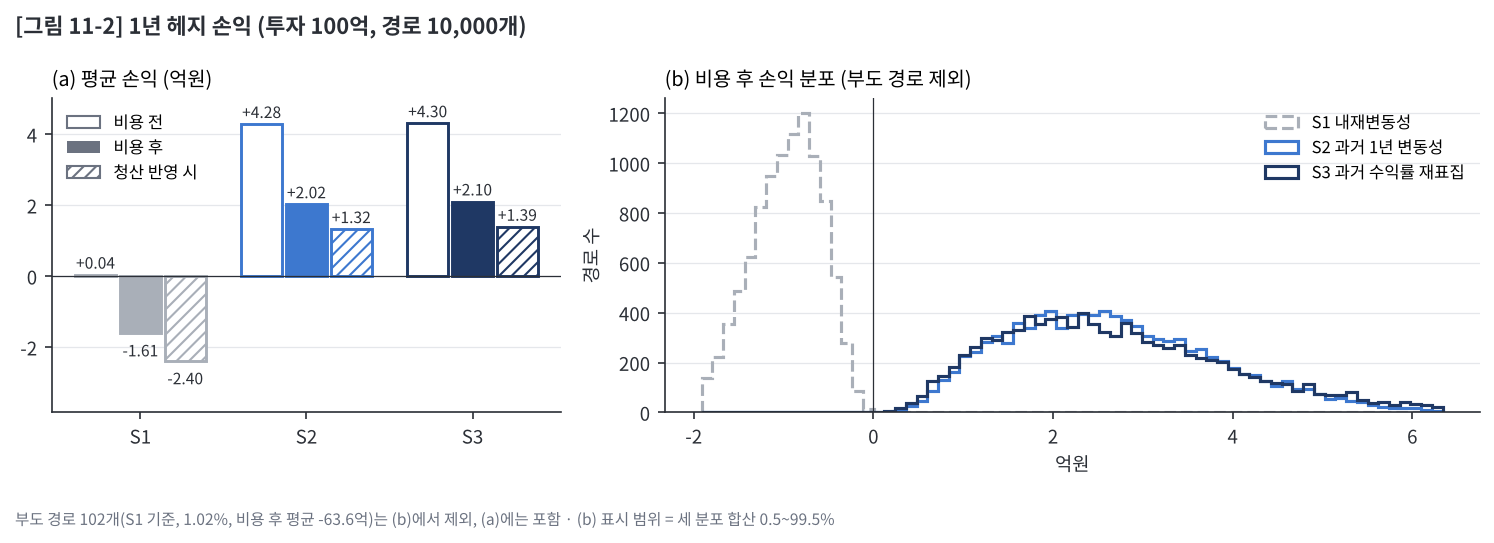

In [8]:
p0 = P(SIG); o = eb.price_fdm(p0, keep=True)                          # 시간 × 주가 격자의 EB 가격
SC = {'S1 내재변동성': dict(sigma_real=SIG), 'S2 과거 1년 변동성': dict(sigma_real=HV), 'S3 과거 수익률 재표집': dict(boot=RET)}
COST = dict(sell_tax=CFG['sell_tax'], k_tick=CFG['k_tick'], borrow=CFG['borrow'], Y=CFG['Y'], sd_d=SD60, adv=ADV)
MC = {k: eb.hedge_mc(o, p0, CFG['notional'], n=CFG['mc_n'], steps=CFG['mc_days'], seed=CFG['seed'], **COST, **v)
      for k, v in SC.items()}                                         # 부도 난수는 세 시나리오 공통 (같은 시드라 S1 · S2는 주가 난수도 공통)
def row(k, m):
    x0, x = m['pnl'] / 1e8, m['pnl_cost'] / 1e8
    xe = sl.mc_exit_cost(m, CFG['notional'], SD60, ADV, CFG['bidask'], CFG['k_tick'], CFG['Y']) / 1e8; xx = x - xe   # 청산 반영 시
    return {'시나리오': k, '실현 변동성': float(np.sqrt(np.nanmean(m['vol'] ** 2))), '비용 전 평균': x0.mean(), '표준오차': x0.std(ddof=1) / math.sqrt(len(x0)),
            '거래비용': m['cost'].mean() / 1e8, '그중 첫날': m['cost0'].mean() / 1e8, '비용 후 평균': x.mean(), '비용 후 5%': np.percentile(x, 5), '비용 후 95%': np.percentile(x, 95),
            '비용 후 손실 확률': (x < 0).mean(), '청산 비용': xe.mean(), '청산 반영 시 평균': xx.mean(), '청산 반영 시 손실 확률': (xx < 0).mean(),
            '부도 경로': m['defaults'], '조기 교환 경로': m['exchanged']}
HM = pd.DataFrame([row(k, m) for k, m in MC.items()])
show(HM.drop(columns='표준오차'), {**{k: '{:+.3f}' for k in ['비용 전 평균', '비용 후 평균', '비용 후 5%', '비용 후 95%', '청산 반영 시 평균']},
                                  **{k: '{:.3f}' for k in ['거래비용', '그중 첫날', '청산 비용']},
                                  '실현 변동성': '{:.2%}', '비용 후 손실 확률': '{:.2%}', '청산 반영 시 손실 확률': '{:.2%}'})
print('손익 단위: 억원 · 청산 반영 시 = 비용 후 − 청산 비용(252영업일째 EB 매도 호가 차이 절반 + 공매도 상환) · 비용 전 = EB 평가손익 − 공매도 수량 × 주가 변화 + 공매도 대금 이자 − 배당 지급(q) − EB 매입대금 조달(모두 모형 금리 r)')
print('거래비용 = 반 틱 + 시장충격 + 매도세 + 대차료 (그중 첫날 = 첫 공매도 비용) · 비용 후 = 비용 전 − 거래비용 · 실현 변동성 = 경로별 분산 평균의 제곱근 · 시간: 1영업일 = 1/252년')
k1, k2, k3 = SC
chk.check('S1: |비용 전 평균| ≤ 3SE', bool(abs(HM.loc[0, '비용 전 평균']) <= 3 * HM.loc[0, '표준오차']), True)
rms = lambda k: float(np.sqrt(np.nanmean(MC[k]['vol'] ** 2)))          # 경로별 분산 평균의 제곱근 (경로별 표준편차 평균은 하향 편향)
chk.check('S2 실현 변동성(분산 평균) ≈ HV252', rms(k2), HV, 0.005)
chk.check('S3 실현 변동성(분산 평균) ≈ 표본 변동성', rms(k3), RET.std(ddof=0) * math.sqrt(252), 0.01)
sd1 = float((MC[k1]['pnl'][~MC[k1]['dflt']] / 1e8).std(ddof=1))
sd0 = float(MC[k1]['h0'][0]) * SV * SIG * math.sqrt(CFG['mc_days'] / 252) / 1e8   # 헤지하지 않았을 때 손익 표준편차 근사 = 공매도 주식수 × 주가 × σ√T
chk.check('헤지 효과: S1 비용 전 손익 표준편차(부도 제외) ≤ 미헤지 근사의 10%', bool(sd1 <= 0.1 * sd0), True)
print(f"헤지 효과: S1 비용 전 손익 표준편차(부도 제외) {sd1:.3f}억 vs 헤지하지 않았을 때 근사 {sd0:.2f}억 ({sd1 / sd0:.1%})")
pd_ = 1 - math.exp(-lam * CFG['mc_days'] / 252)
chk.check(f"부도 경로 비율 ≈ 1 − e^(−λ·{CFG['mc_days'] / 252:g}년) (3SE)", abs(MC[k1]['defaults'] / CFG['mc_n'] - pd_) <= 3 * math.sqrt(pd_ * (1 - pd_) / CFG['mc_n']), True)

# [그림 11-2] 1년 헤지 손익
COL = dict(zip(SC, (C1, C2, C3))); LS = dict(zip(SC, ('--', '-', '-')))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={'width_ratios': [1, 1.6]})
w = 0.27
for i, (k, m) in enumerate(MC.items()):
    for dx, y, fill in [(-w, m['pnl'].mean() / 1e8, 'none'), (0.0, m['pnl_cost'].mean() / 1e8, 'full'), (w, HM.loc[i, '청산 반영 시 평균'], 'hatch')]:
        a1.bar(i + dx, y, w * 0.92, facecolor=COL[k] if fill == 'full' else 'white', edgecolor=COL[k], lw=1.4, hatch='////' if fill == 'hatch' else None)
        a1.annotate(f'{(round(y, 2) or 0.0):+.2f}', (i + dx, y), xytext=(0, 3 if y >= 0 else -11), textcoords='offset points', ha='center', fontsize=7.5, color=rs.INK)
a1.axhline(0, color=rs.INK, lw=0.6); a1.set_xticks(range(len(MC)), [k.split()[0] for k in MC])
lo1, hi1 = a1.get_ylim(); a1.set_ylim(lo1 - 0.15 * (hi1 - lo1), hi1 + 0.05 * (hi1 - lo1))
a1.legend(handles=[Patch(facecolor='white', edgecolor=rs.MUTED, label='비용 전'), Patch(facecolor=rs.MUTED, label='비용 후'),
                   Patch(facecolor='white', edgecolor=rs.MUTED, hatch='////', label='청산 반영 시')], frameon=False, fontsize=8, loc='upper left')
a1.set_title('(a) 평균 손익 (억원)')
ok = {k: m['pnl_cost'][~m['dflt']] / 1e8 for k, m in MC.items()}
bins = np.linspace(*np.percentile(np.concatenate(list(ok.values())), [0.5, 99.5]), 70)
for k, x in ok.items():
    a2.hist(x, bins=bins, histtype='step', lw=1.5, color=COL[k], ls=LS[k], label=k)
a2.axvline(0, color=rs.INK, lw=0.6); a2.legend(frameon=False, fontsize=8, loc='upper right')
a2.set_xlabel('억원'); a2.set_ylabel('경로 수'); a2.set_title('(b) 비용 후 손익 분포 (부도 경로 제외)')
nd = MC[k1]['defaults']; dm = MC[k1]['pnl_cost'][MC[k1]['dflt']].mean() / 1e8
rs.finish(fig, f'[그림 11-2] 1년 헤지 손익 (투자 {CFG["notional"] / 1e8:,.0f}억, 경로 {CFG["mc_n"]:,}개)',
          f'부도 경로 {nd}개(S1 기준, {nd / CFG["mc_n"]:.2%}, 비용 후 평균 {dm:+.1f}억)는 (b)에서 제외, (a)에는 포함 · (b) 표시 범위 = 세 분포 합산 0.5~99.5%')
plt.show()

### 5-2 공매도 수량 점검
- 공매도 잔고 공시 의무: 상장주식 수의 0.01% 이상(평가액 1억원 미만 제외) 또는 평가액 10억원 이상 (2024-12-01 시행)

In [9]:
h1 = float(MC[k1]['h0'][0])                                          # 첫날 공매도 주식수 (세 시나리오 동일)
thr = min(max(CFG['disc_ratio'] * NLIST, CFG['disc_min'] / SV), CFG['disc_amt'] / SV)   # 공시 의무 최소 수량
def tq(k, qq):                                                       # 일별 재조정 주식수 분위 (거래가 있는 날, 조기 교환 · 부도로 끝난 날의 청산 거래 제외)
    T_ = np.abs(MC[k]['trades'][1:]); end = MC[k]['dflt'] | MC[k]['exch']
    last = T_.shape[0] - 1 - (T_ > 0)[::-1].argmax(axis=0)            # 경로별 마지막 거래일 = 교환 · 부도일
    T_ = T_.copy(); T_[last[end], np.nonzero(end)[0]] = 0.0
    t_ = T_.ravel(); return np.percentile(t_[t_ > 0], qq)
FE = pd.DataFrame([('첫날 공매도', h1), ('일별 재조정 95% 분위 — S2', tq(k2, 95)), ('일별 재조정 95% 분위 — S3', tq(k3, 95)),
                   ('일별 재조정 99% 분위 — S2', tq(k2, 99)), ('일별 재조정 99% 분위 — S3', tq(k3, 99)),
                   ('공시 의무 최소 수량', thr)], columns=['항목', '주식수'])
FE['금액 (억원)'] = FE['주식수'] * SV / 1e8; FE['60일 평균 거래량 대비'] = FE['주식수'] / ADV; FE['상장주식 대비'] = FE['주식수'] / NLIST
show(FE, {'주식수': '{:,.0f}', '금액 (억원)': '{:.2f}', '60일 평균 거래량 대비': '{:.1%}', '상장주식 대비': '{:.3%}'})
chk.check('첫날 공매도 ≥ 공시 의무 최소 수량', bool(h1 >= thr), True); print(f"첫날 공매도 {h1:,.0f}주 {'≥' if h1 >= thr else '<'} 공시 의무 최소 수량 {thr:,.0f}주 → 공매도 잔고 공시 {'대상' if h1 >= thr else '대상 아님'} (금액 = 주식수 × 평가 주가 {SV:,.0f}원)")

,항목,주식수,금액 (억원),60일 평균 거래량 대비,상장주식 대비
0,첫날 공매도,"18,573",32.65,18.5%,0.041%
1,일별 재조정 95% 분위 — S2,"1,631",2.87,1.6%,0.004%
2,일별 재조정 95% 분위 — S3,"1,609",2.83,1.6%,0.004%
3,일별 재조정 99% 분위 — S2,"2,201",3.87,2.2%,0.005%
4,일별 재조정 99% 분위 — S3,"2,597",4.57,2.6%,0.006%
5,공시 의무 최소 수량,"4,483",7.88,4.5%,0.010%


✓ 첫날 공매도 ≥ 공시 의무 최소 수량: True | 기대 True
첫날 공매도 18,573주 ≥ 공시 의무 최소 수량 4,483주 → 공매도 잔고 공시 대상 (금액 = 주식수 × 평가 주가 175,800원)


## 6. 금리 민감도와 국채선물 필요 계약 수 (참고)
- 5절 헤지 MC는 금리 · 스프레드를 10/27 값으로 고정 → 금리 헤지 효과는 시뮬레이션하지 않고, 평가일의 필요 수량만 제시 (10번 6절과 같은 방식)
- EB 금리 민감도(DV01): 5절과 같은 FDM(σ = 즉시 콜 내재변동성)에서 국고 금리 r만 ±1bp(신용스프레드 s 고정) → 금리 1bp 상승 시 투자 100억의 손실(원)
- 선물: 3년 국채선물 12월물(10번 6절과 같은 이유) · 10/27 정산가 기준 1계약 DV01 · 12월물 최종거래일(12/15) 전에 다음 월물로 교체 필요

In [10]:
KRX = pd.read_csv(PROJ / 'data' / '20261109' / 'krx_ktbf_daily_20260701_20261106.csv', dtype=str, encoding='utf-8-sig')   # KRX 원자료 (10번 6절과 같은 파일)
KRX['일자'] = KRX['TRD_DD'].str[:10].str.replace('/', ''); KRX = KRX[~KRX['TRD_DD'].str.contains('야간')]
F_mkt = float(KRX[(KRX['종류'] == '3y') & (KRX['월물'] == '202612') & (KRX['일자'] == CFG['mkt_date'])]['SETL_PRC'].str.replace(',', '').iloc[0])
hb = 1e-4
up = eb.price_fdm(eb.setup(SV, SIG, r + hb, q, s, CFG['val']))['price']; dn = eb.price_fdm(eb.setup(SV, SIG, r - hb, q, s, CFG['val']))['price']
DV_EB = (dn - up) / 2 * CFG['notional'] / 100                               # 금리 1bp 상승 시 손실(원)
DV_F = sl.ktbf_dv01(F_mkt, 3); NF = int(round(DV_EB / DV_F))
chk.check('EB 100억 DV01 (원/bp)', DV_EB, basis=f"3년 국채선물 12월물 10/27 정산가 {F_mkt:.2f} · 1계약 DV01 {DV_F:,.0f}원 → {NF}계약 매도", kind='info')
print(f"EB 100억 금리 1bp 상승 시 {DV_EB / 1e4:,.1f}만원 손실 (액면 100당 {(dn - up) / 2:.4f}p) → 3년 국채선물 {NF}계약 매도 (1계약 DV01 {DV_F:,.0f}원, 10/27 정산가 {F_mkt:.2f})")

ℹ EB 100억 DV01 (원/bp): 2161497.640052801  (3년 국채선물 12월물 10/27 정산가 103.34 · 1계약 DV01 28,661원 → 75계약 매도)
EB 100억 금리 1bp 상승 시 216.1만원 손실 (액면 100당 0.0216p) → 3년 국채선물 75계약 매도 (1계약 DV01 28,661원, 10/27 정산가 103.34)


## 7. 요약

In [11]:
SUMM = pd.DataFrame([
    dict(항목='① 내재변동성', 결과=f"{IV['콜 없음']:.2%} ~ {IV['즉시 콜']:.2%} (HV252 {HV:.2%})", 근거='3절'),
    dict(항목='② 발행가 100의 구성', 결과=f"채권 {DEC.iloc[0, 0]:.2f} + 풋 {DEC.iloc[1, 0]:.2f} + 교환권 {DEC.iloc[2, 0]:.2f} + 콜 {DEC.iloc[4, 0]:+.2f} = {DEC.iloc[5, 0]:.2f} (항목별 반올림이라 합이 0.01 다르게 보일 수 있음)", 근거='3절'),
    dict(항목='③ 1년 헤지 손익 (비용 후 평균 → 청산 반영 시)', 결과=' · '.join(f"{k} {x:+.2f}억 → {y:+.2f}억" for k, x, y in zip(HM['시나리오'], HM['비용 후 평균'], HM['청산 반영 시 평균'])), 근거='5절'),
    dict(항목='④ 공매도 수량', 결과=f"첫날 {h1:,.0f}주 = 60일 평균 거래량의 {h1 / ADV:.1%} · 공매도 잔고 공시 대상", 근거='5-2절'),
    dict(항목='⑤ 금리 민감도', 결과=f"EB 100억 DV01 {DV_EB / 1e4:,.1f}만원/bp → 3년 국채선물 {NF}계약 매도 (헤지 효과는 시뮬레이션하지 않음)", 근거='6절')])
show(SUMM)
for name, df in [('inputs', INP), ('ladder', LADDER), ('iv', IVT), ('decomposition', DEC.reset_index()), ('sensitivity', SEN),
                 ('hedge_mc', HM), ('feasibility', FE)]:
    df.to_csv(OUT / f'11_{name}.csv', index=False, encoding='utf-8-sig')
assert chk.save(OUT / '11_checks.csv') == 0, '✗ 항목 확인'

,항목,결과,근거
0,① 내재변동성,38.92% ~ 39.84% (HV252 63.19%),3절
1,② 발행가 100의 구성,채권 79.86 + 풋 7.45 + 교환권 13.17 + 콜 -0.49 = 100.00 (항목별 반올림이라 합이 0.01 다르게 보일 수 있음),3절
2,③ 1년 헤지 손익 (비용 후 평균 → 청산 반영 시),S1 내재변동성 -1.61억 → -2.40억 · S2 과거 1년 변동성 +2.02억 → +1.32억 · S3 과거 수익률 재표집 +2.10억 → +1.39억,5절
3,④ 공매도 수량,"첫날 18,573주 = 60일 평균 거래량의 18.5% · 공매도 잔고 공시 대상",5-2절
4,⑤ 금리 민감도,EB 100억 DV01 216.1만원/bp → 3년 국채선물 75계약 매도 (헤지 효과는 시뮬레이션하지 않음),6절



점검 48건: ✓ 44 · ✗ 0 · ℹ 4 → 11_checks.csv
